# Convolutional neural networks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/06-deep-learning/cnn/cnn-notebook.ipynb)

Companion notebook for the *Convolutional neural networks* slides. Each idea is written first by hand
with NumPy and then with the SciPy tool that does the same job.

**Data:** the Digits data (1 797 handwritten digits, each a grid of 8 × 8 gray pixels).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import maximum_filter
from scipy.signal import correlate, correlate2d
from sklearn.datasets import load_digits

RANDOM_STATE = 42
STEP_H = 1e-6

images = load_digits().images
image = images[0]
rng = np.random.default_rng(RANDOM_STATE)
print("image shape:", image.shape)

image shape: (8, 8)


## 1. The convolution

Place the $k \times k$ kernel with its corner at row $i$, column $j$, multiply, add up and add the bias:
$Z_{ij} = \sum_{m=0}^{k-1} \sum_{n=0}^{k-1} X_{i+m,\,j+n} \, K_{mn} + b$.
This kernel adds the left column of each patch and subtracts the right one: it finds vertical edges.
In SciPy this operation is `correlate2d`.

In [2]:
def convolve_by_hand(X: np.ndarray, K: np.ndarray, b: float = 0.0) -> np.ndarray:
    """Slide K over X (no padding, stride 1) and fill the feature map."""
    k = K.shape[0]
    n_out = X.shape[0] - k + 1, X.shape[1] - k + 1
    return np.array([[np.sum(X[i:i + k, j:j + k] * K) + b for j in range(n_out[1])] for i in range(n_out[0])])


vertical_edge = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]])
feature_map = convolve_by_hand(image, vertical_edge)
print("feature map shape:", feature_map.shape)
print("same result:", np.allclose(feature_map, correlate2d(image, vertical_edge, mode="valid")))

feature map shape: (6, 6)
same result: True


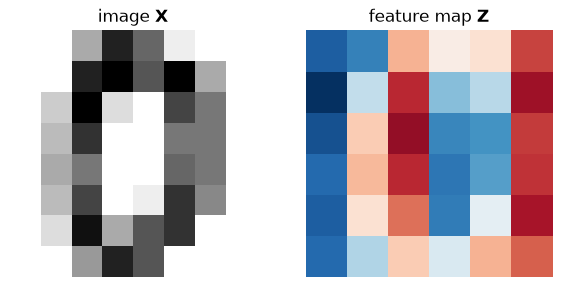

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(image, cmap="gray_r")
axes[0].set_title("image $\\mathbf{X}$")
axes[1].imshow(feature_map, cmap="RdBu_r", vmin=-np.abs(feature_map).max(), vmax=np.abs(feature_map).max())
axes[1].set_title("feature map $\\mathbf{Z}$")
for ax in axes:
    ax.axis("off")
plt.show()

## 2. Padding and stride

Padding $p$ adds a border of zeros; stride $s$ is how far the kernel jumps.
The output side is $n_{\text{out}} = \left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1$.

In [4]:
def output_size(n: int, k: int, p: int, s: int) -> int:
    return (n + 2 * p - k) // s + 1


padded_by_hand = convolve_by_hand(np.pad(image, 1), vertical_edge)
print(f"p = 1, s = 1: shape {padded_by_hand.shape}, formula {output_size(8, 3, 1, 1)}",
      "| same result:", np.allclose(padded_by_hand, correlate2d(image, vertical_edge, mode="same")))

strided_by_hand = np.array([[np.sum(image[i:i + 3, j:j + 3] * vertical_edge) for j in range(0, 6, 2)] for i in range(0, 6, 2)])
print(f"p = 0, s = 2: shape {strided_by_hand.shape}, formula {output_size(8, 3, 0, 2)}",
      "| same result:", np.allclose(strided_by_hand, correlate2d(image, vertical_edge, mode="valid")[::2, ::2]))

p = 1, s = 1: shape (8, 8), formula 8 | same result: True
p = 0, s = 2: shape (3, 3), formula 3 | same result: True


## 3. Channels, filters and ReLU

With $C$ channels each kernel is $k \times k \times C$ and sums over all of them:
$Z^{(f)}_{ij} = \sum_{c} \sum_{m} \sum_{n} X_{i+m,\,j+n,\,c} \, K^{(f)}_{mnc} + b^{(f)}$.
ReLU then keeps the positive entries: $A_{ij} = \max(0, Z_{ij})$.
Here three digits play the role of the three color channels.

In [5]:
color_image = np.stack(images[:3], axis=-1)
kernel = rng.normal(size=(3, 3, 3))
bias = 0.5

Z_by_hand = sum(correlate2d(color_image[:, :, c], kernel[:, :, c], mode="valid") for c in range(3)) + bias
Z_scipy = correlate(color_image, kernel, mode="valid")[:, :, 0] + bias
print("same result:", np.allclose(Z_by_hand, Z_scipy))

A = np.maximum(0, Z_by_hand)
print(f"ReLU sets {np.mean(A == 0):.0%} of the entries to 0")
print("parameters of one filter, k*k*C + 1 =", kernel.size + 1)

same result: True
ReLU sets 53% of the entries to 0
parameters of one filter, k*k*C + 1 = 28


## 4. Pooling

Max pooling keeps the largest value of each $2 \times 2$ window (stride 2), so the map shrinks by half.
It has no weights to learn.

In [6]:
pooled_by_hand = A.reshape(3, 2, 3, 2).max(axis=(1, 3))
pooled_scipy = maximum_filter(A, size=2, origin=-1)[::2, ::2]
print("shape", A.shape, "->", pooled_by_hand.shape, "| same result:", np.allclose(pooled_by_hand, pooled_scipy))

shape (6, 6) -> (3, 3) | same result: True


## 5. The gradient of a shared weight

Each kernel weight is used at every position, so its gradient adds up all of them:
$\dfrac{\partial L}{\partial K_{mn}} = \sum_i \sum_j \dfrac{\partial L}{\partial Z_{ij}} \, X_{i+m,\,j+n}$.
With the toy loss $L = \frac{1}{2}\sum_{ij} Z_{ij}^2$ we have $\partial L / \partial Z_{ij} = Z_{ij}$.

In [7]:
def toy_loss(K: np.ndarray) -> float:
    return 0.5 * np.sum(correlate2d(image, K, mode="valid") ** 2)


K = rng.normal(size=(3, 3))
dL_dZ = correlate2d(image, K, mode="valid")
gradient_by_hand = np.array([[np.sum(dL_dZ * image[m:m + 6, n:n + 6]) for n in range(3)] for m in range(3)])

numeric = np.zeros_like(K)
for m, n in np.ndindex(K.shape):
    nudge = np.zeros_like(K)
    nudge[m, n] = STEP_H
    numeric[m, n] = (toy_loss(K + nudge) - toy_loss(K - nudge)) / (2 * STEP_H)
print("same result:", np.allclose(gradient_by_hand, numeric, rtol=1e-4))

same result: True


## Exercises

1. Use the horizontal-edge kernel (the transpose of `vertical_edge`) in section 1 and compare both feature maps.
2. Write average pooling by hand and compare it with `scipy.ndimage.uniform_filter(A, size=2, origin=-1)[::2, ::2]`.
3. Count the parameters of a layer with 64 filters of size $3 \times 3$ on a color image, and of a dense layer from a $200 \times 200 \times 3$ image to 1 000 neurons.